## Epilog EDA
Zur visualisierung und Dokumentation der Ergebnisse der Datananalyse und Kundenkategorisierung werden in diesem Notebook die Kundengruppen und Perks, sowie die Verteilung aufbereitet.

# Zelle 1
Verteilung der Perks (Absolute & Prozentuale Anteile):

Erfolgreich 50,000 Kundenzuweisungen für den Prolog geladen.


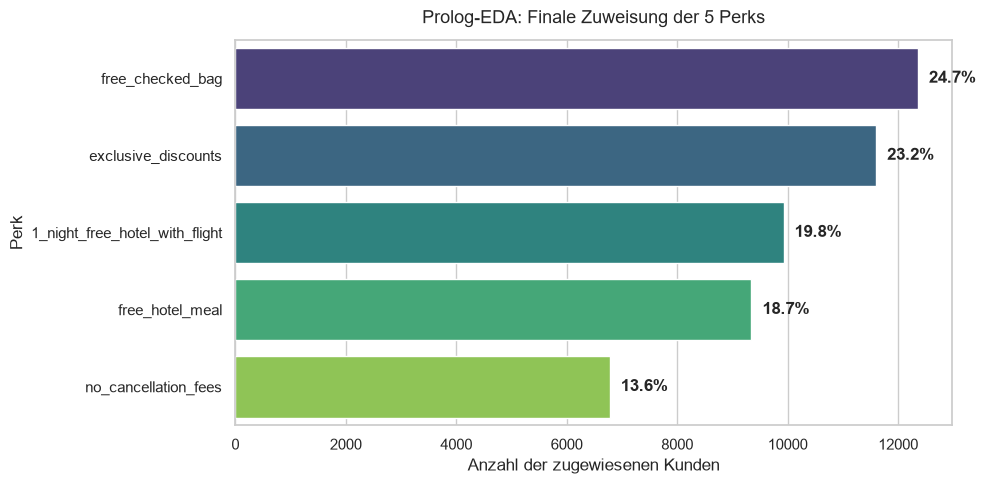

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Design-Settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# 1. Finales Zuordnungs-Artefakt laden
df_perks = pd.read_csv('data/perk_assignments.csv')
df_demo = pd.read_csv('data/traveltide_user_aggregated_eda.csv')

# Zusammenführen von Demographie und Perk-Assignments
df_summary = df_perks.merge(df_demo, on='user_id')

print(f"Erfolgreich {len(df_summary):,} Kundenzuweisungen für den Prolog geladen.")

# 2. Graph 1: Gesamtverteilung der Perks
plt.figure(figsize=(10, 5))
perk_counts = df_summary['assigned_perk'].value_counts()
ax = sns.barplot(x=perk_counts.values, y=perk_counts.index, hue=perk_counts.index, legend=False, palette="viridis")

plt.title("Prolog-EDA: Finale Zuweisung der 5 Perks", fontsize=13, pad=12)
plt.xlabel("Anzahl der zugewiesenen Kunden")
plt.ylabel("Perk")

# Prozentuale Beschriftung hinzufügen
total = len(df_summary)
for p in ax.patches:
    pct = f'{(p.get_width() / total) * 100:.1f}%'
    ax.annotate(pct, (p.get_width() + 200, p.get_y() + p.get_height() / 2), ha='left', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

Prolog-EDA: 50,000 Kundenzuweisungen erfolgreich mit Demografie verknüpft.


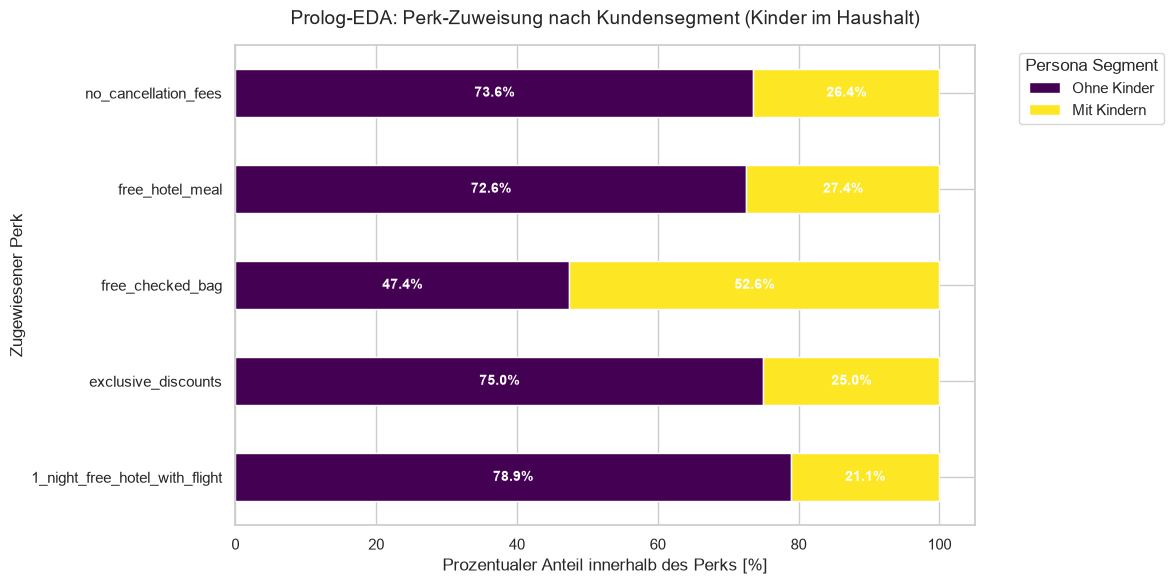

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Design-Einstellungen
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 1. Daten laden
df_perks = pd.read_csv('data/perk_assignments.csv')
df_demo = pd.read_csv('data/traveltide_user_aggregated_eda.csv')

# 2. Mergen über user_id für den vollen Kontext
df_summary = df_perks.merge(df_demo, on='user_id')

print(f"Prolog-EDA: {len(df_summary):,} Kundenzuweisungen erfolgreich mit Demografie verknüpft.")

# 3. Persona-Analyse: Perk-Verteilung nach Familienstatus (has_children)
ct_children = pd.crosstab(
    df_summary['assigned_perk'], 
    df_summary['has_children'], 
    normalize='index'
) * 100

# Mapping für bessere Lesbarkeit im Plot
ct_children.columns = ['Ohne Kinder', 'Mit Kindern']

# 4. Visualisierung: Gestapeltes Diagramm (Persona Overlap)
ax = ct_children.plot(kind='barh', stacked=True, colormap='viridis', figsize=(12, 6))

plt.title("Prolog-EDA: Perk-Zuweisung nach Kundensegment (Kinder im Haushalt)", fontsize=14, pad=15)
plt.xlabel("Prozentualer Anteil innerhalb des Perks [%]", fontsize=12)
plt.ylabel("Zugewiesener Perk", fontsize=12)
plt.legend(title="Persona Segment", bbox_to_anchor=(1.05, 1), loc='upper left')

# Beschriftung der Prozentwerte in den Balken
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

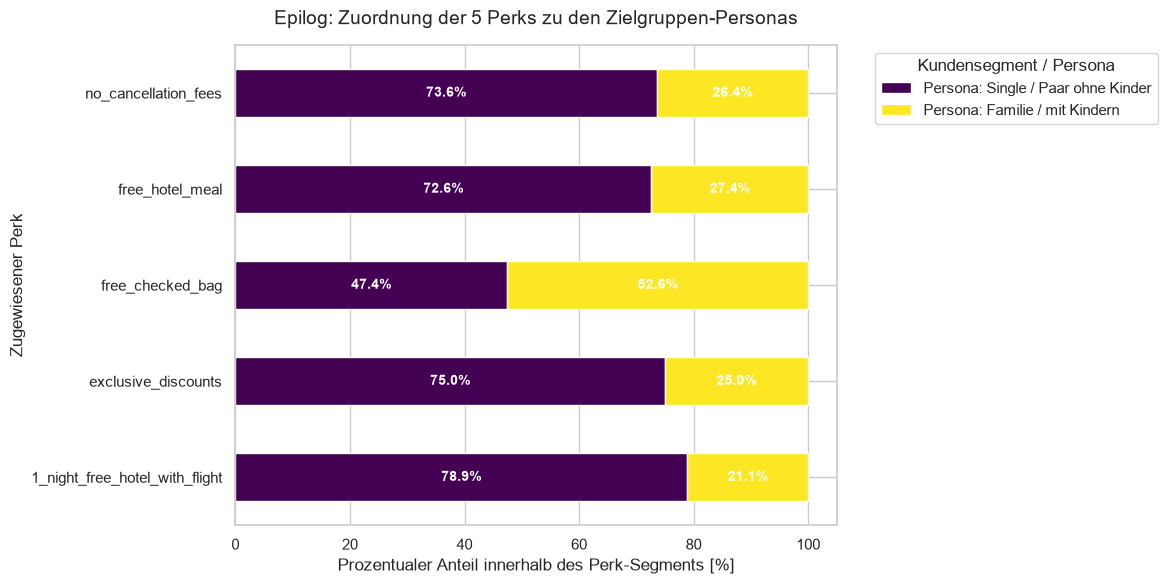

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Design-Konfiguration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 1. Daten laden (Zuordnungs-Artefakt + Demografie/Verhalten)
df_perks = pd.read_csv('data/perk_assignments.csv')
df_demo = pd.read_csv('data/traveltide_user_aggregated_eda.csv')

# Mergen über user_id
df_summary = df_perks.merge(df_demo, on='user_id')

# 2. Beispiel: Zuordnung von Verhaltens-Personas (z.B. Familien vs. Nicht-Familien)
# Je nach Merkmalen kannst du hier deine 5 expliziten Personas abbilden
ct_personas = pd.crosstab(
    df_summary['assigned_perk'], 
    df_summary['has_children'], 
    normalize='index'
) * 100

ct_personas.columns = ['Persona: Single / Paar ohne Kinder', 'Persona: Familie / mit Kindern']

# 3. Visualisierung
ax = ct_personas.plot(
    kind='barh', 
    stacked=True, 
    colormap='viridis', 
    figsize=(12, 6)
)

plt.title("Epilog: Zuordnung der 5 Perks zu den Zielgruppen-Personas", fontsize=14, pad=15)
plt.xlabel("Prozentualer Anteil innerhalb des Perk-Segments [%]", fontsize=12)
plt.ylabel("Zugewiesener Perk", fontsize=12)
plt.legend(title="Kundensegment / Persona", bbox_to_anchor=(1.05, 1), loc='upper left')

# Prozentwerte auf den Balken anzeigen
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

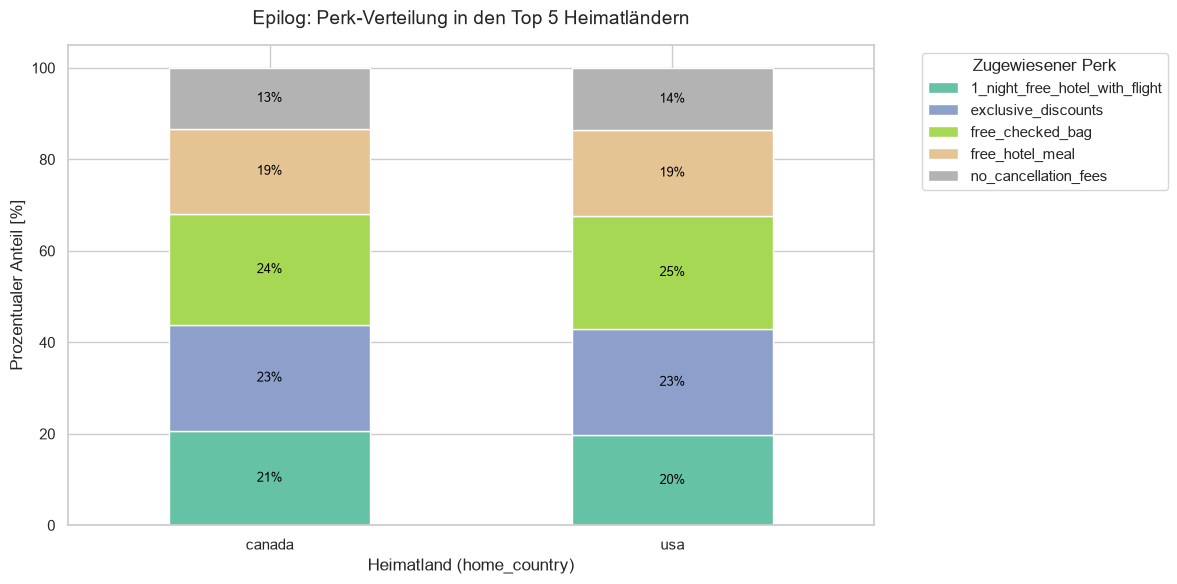

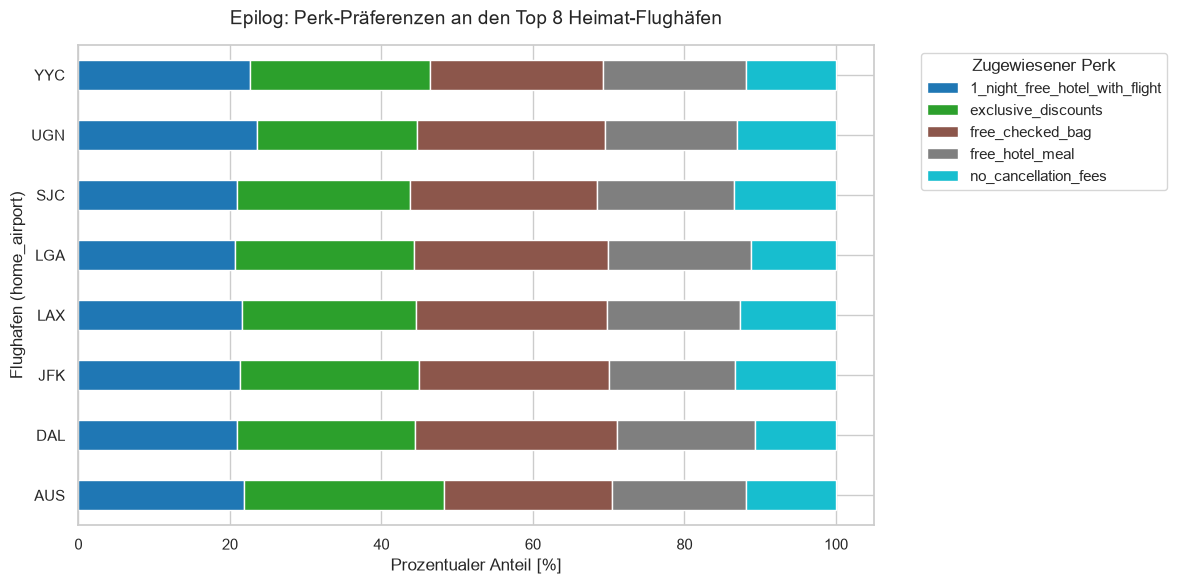

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Design-Settings
sns.set_theme(style="whitegrid")

# 1. Daten laden (Achte auf deinen Pfad)
df_perks = pd.read_csv('data/perk_assignments.csv')
df_demo = pd.read_csv('data/traveltide_user_aggregated_eda.csv')

# Mergen über user_id
df_summary = df_perks.merge(df_demo, on='user_id')

# ---------------------------------------------------------
# ANALYSE 1: Top 5 Länder nach Perk-Verteilung
# ---------------------------------------------------------
top_countries = df_summary['home_country'].value_counts().head(5).index
df_top_countries = df_summary[df_summary['home_country'].isin(top_countries)]

ct_country = pd.crosstab(
    df_top_countries['home_country'], 
    df_top_countries['assigned_perk'], 
    normalize='index'
) * 100

ax1 = ct_country.plot(
    kind='bar', 
    stacked=True, 
    colormap='Set2', 
    figsize=(12, 6)
)

plt.title("Epilog: Perk-Verteilung in den Top 5 Heimatländern", fontsize=14, pad=15)
plt.xlabel("Heimatland (home_country)", fontsize=12)
plt.ylabel("Prozentualer Anteil [%]", fontsize=12)
plt.legend(title="Zugewiesener Perk", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)

# Beschriftung in den Balken
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.0f%%', label_type='center', color='black', fontsize=9)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANALYSE 2: Top 8 Flughäfen (Home Airport) nach Perks
# ---------------------------------------------------------
top_airports = df_summary['home_airport'].value_counts().head(8).index
df_top_airports = df_summary[df_summary['home_airport'].isin(top_airports)]

ct_airport = pd.crosstab(
    df_top_airports['home_airport'], 
    df_top_airports['assigned_perk'], 
    normalize='index'
) * 100

ax2 = ct_airport.plot(
    kind='barh', 
    stacked=True, 
    colormap='tab10', 
    figsize=(12, 6)
)

plt.title("Epilog: Perk-Präferenzen an den Top 8 Heimat-Flughäfen", fontsize=14, pad=15)
plt.xlabel("Prozentualer Anteil [%]", fontsize=12)
plt.ylabel("Flughafen (home_airport)", fontsize=12)
plt.legend(title="Zugewiesener Perk", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()